# Delivery and exhaust-air heat pumps

Distinguish thermal demand from capacity-limited FVP delivery and backup energy.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`DeliverySpec(fvp=FVPSpec(...))` adds the package's exhaust-air heat-pump estimate to a compatible building. FVP production is limited by demand, nominal thermal capacity and sensible heat available in the prescribed exhaust flow. The model uses a supplied constant COP rather than solving a refrigerant cycle.

Separate the thermal demands from delivery components: `fvp_heat_kwh` is produced heat, `fvp_electricity_kwh` is its electrical input, and `backup_input_kwh` is residual demand divided by backup efficiency. The workflow figure's result stage therefore contains several related streams, not one interchangeable energy total.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### FVP heat and electricity accounting

Conceptual accounting: recovered source heat plus compressor electricity supplies heat-pump output. Capacity and source availability constrain recovery. The hourly outputs below come from the package delivery calculation following the thermal simulation. Keep thermal demand, delivered heat and purchased electricity separate; this diagram supplies no assumed efficiency or numerical result.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

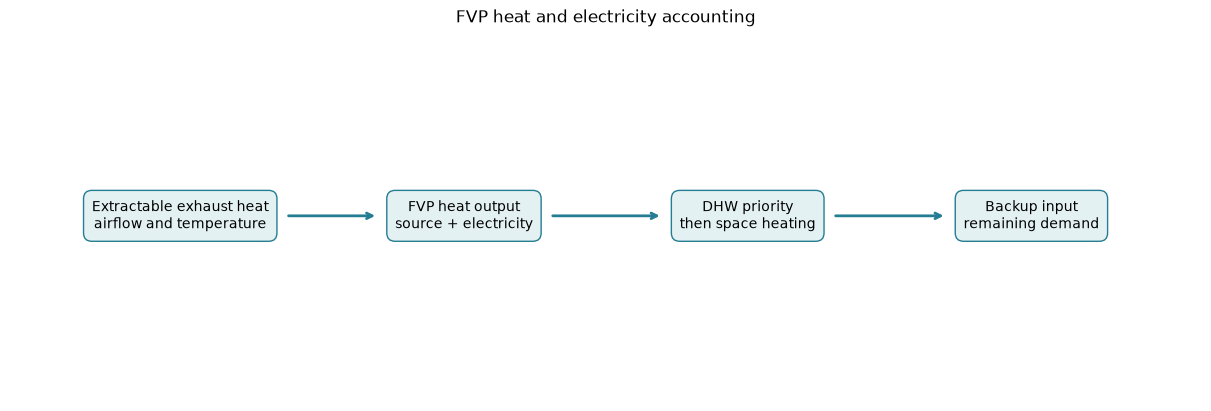

In [2]:
from demo.support.common import flow
flow(['Extractable exhaust heat\nairflow and temperature', 'FVP heat output\nsource + electricity', 'DHW priority\nthen space heating', 'Backup input\nremaining demand'], 'FVP heat and electricity accounting', figsize=(12, 4))

## Configure compatible FVP delivery

The model uses an explicit COP, thermal capacity and exhaust-temperature threshold. This is the package delivery model, not a detailed refrigerant-cycle simulation.

### Read the code and output

The exhaust-only `F` airflow is a compatibility choice for this example. Read thermal capacity in kW and the exhaust threshold in °C. `dhw_priority` decides which thermal load gets available production first; it does not increase available source heat or installed capacity.

,field,value
0,cop,3.0
1,capacity_kw,8.0
2,exhaust_min_temperature_c,5
3,dhw_priority,True
4,backup_efficiency,1


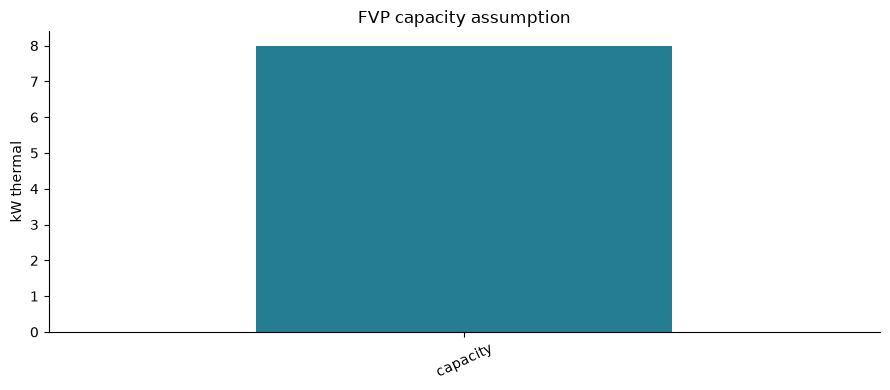

In [3]:
b=building()
b=b.updated(airflow=AirflowSpec(topology="F",envelope_infiltration_ach=.2,mechanical_vent_l_s_m2=.35),delivery=DeliverySpec(fvp=FVPSpec(cop=3,capacity_kw=8,dhw_priority=True)))
table(b.delivery.fvp.model_dump())
bars({"capacity":b.delivery.fvp.capacity_kw},"kW thermal","FVP capacity assumption")

## Run and inspect delivery signals

The runner adds delivery arrays after thermal simulation. Exhaust availability and demand can both limit production; backup serves the remaining demand.

### Read the code and output

In the hourly plot, generated heat and electricity are related components, so summing every displayed column would double count energy. Backup supplies residual demand with its own input definition. The array units are kWh per one-hour interval; a capacity limit in kW is comparable over that fixed interval.

,field,value
0,fvp_heat_kwh,kWh
1,fvp_electricity_kwh,kWh
2,backup_input_kwh,kWh
3,fvp_extracted_heat_kwh,kWh


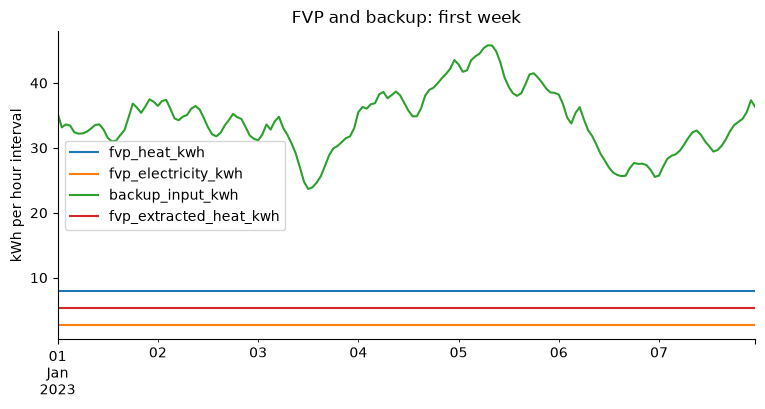

In [4]:
result=EnergyPlusRunner(engine()).run(b,OUT/"fvp")
frame=result_frame(result)
keys=[k for k in frame if k.startswith("fvp_") or k.startswith("backup_")]
table({k:result.units[k] for k in keys})
fig, ax = plt.subplots(figsize=(9, 4))
frame[keys].iloc[:168].plot(ax=ax, ylabel="kWh per hour interval",title="FVP and backup: first week"); plt.show(); plt.close(fig)

## Check the energy balance

Produced heat equals electricity plus extracted exhaust heat for the constant COP model. This check is independent of how much backup is needed.

### Read the code and output

The independent balance is `heat = electricity + extracted_exhaust_heat`. It checks the constant-COP accounting for the supplied small arrays. It does not demonstrate seasonal COP calibration, latent heat extraction or a detailed compressor model. Interpret the annual totals within those stated assumptions.

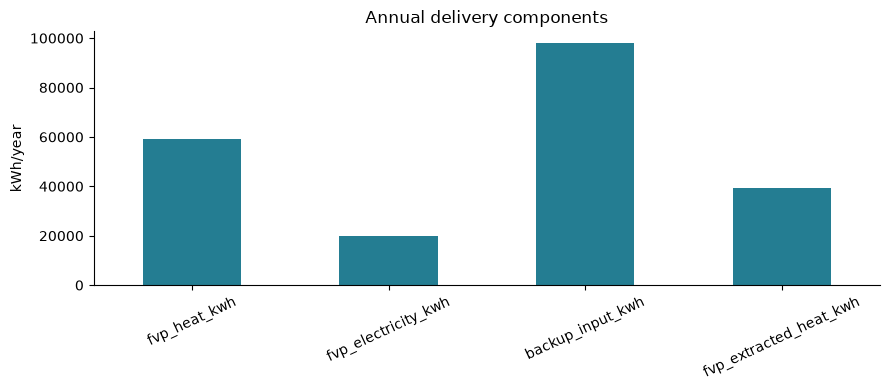

In [5]:
from epsm_core.delivery import fvp_delivery
check=fvp_delivery(b,[10.,2.],[1.,1.],[21.,21.])
assert np.allclose(check["fvp_heat_kwh"],check["fvp_electricity_kwh"]+check["fvp_extracted_heat_kwh"])
bars({k:float(frame[k].sum()) for k in keys},"kWh/year","Annual delivery components")

## Interpretation and next experiment

Do not subtract PV from thermal demand. Report delivered heat, FVP electricity, backup energy and PV generation with their own units and definitions.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.